# Part VII — The verdict: model against reality
**Question:** *could we have predicted the 2026 season, race by race?* Before each 2026 race, every model is re-trained on everything that happened before it (PCA and k-means included), exactly like a live forecast. Then we compare with what really happened.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
S = json.load(open('../results/summary.json')); P = pd.read_csv('../results/predictions.csv')
from f1duel.model import scorers_named, pick10
Q = P[P.test == '2026']
rows = []
for (r, gp), g in Q.groupby(['round', 'gp_name']):
    fav = g.loc[g.p_win.idxmax()]; win = g[g.win == 1]
    rows.append({'Round': r, 'Grand Prix': gp,
                 'Grid rule': int(g.top10[pick10(g, 'grid', True) == 1].sum()),
                 'Model': int(g.top10[pick10(g, 'p_top10_logit') == 1].sum()),
                 'Model favourite': f"{fav.driver_name} ({fav.p_win:.0%})",
                 'Real winner': win.driver_name.iloc[0] if len(win) else '—'})
T = pd.DataFrame(rows).set_index('Round'); T

,Grand Prix,Grid rule,Model,Model favourite,Real winner
Round,,,,,
1,Australia,8,7,George Russell (68%),George Russell
2,China,8,8,Kimi Antonelli (63%),Kimi Antonelli
3,Japan,7,8,Kimi Antonelli (60%),Kimi Antonelli
4,Miami,8,8,Kimi Antonelli (52%),Kimi Antonelli
5,Canada,6,6,George Russell (57%),Kimi Antonelli
6,Monaco,6,6,Kimi Antonelli (72%),Kimi Antonelli
7,Barcelona-Catalunya,7,8,George Russell (65%),Lewis Hamilton
8,Austria,10,10,George Russell (55%),George Russell
9,Great Britain,7,7,Kimi Antonelli (57%),Charles Leclerc


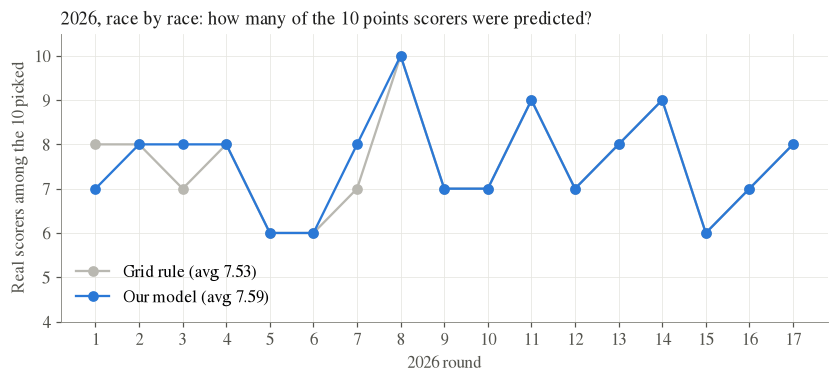

Model better in 2 races, equal in 14, worse in 1.


In [2]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(T.index, T['Grid rule'], 'o-', color=GREY, label=f"Grid rule (avg {T['Grid rule'].mean():.2f})")
ax.plot(T.index, T['Model'], 'o-', color=BLUE, label=f"Our model (avg {T['Model'].mean():.2f})")
ax.set_xticks(T.index); ax.set_xlabel('2026 round'); ax.set_ylabel('Real scorers among the 10 picked'); ax.set_ylim(4, 10.5); ax.legend(loc='lower left')
title(ax, '2026, race by race: how many of the 10 points scorers were predicted?'); save(fig, '07_2026'); plt.show()
print(f"Model better in {(T.Model > T['Grid rule']).sum()} races, equal in {(T.Model == T['Grid rule']).sum()}, worse in {(T.Model < T['Grid rule']).sum()}.")

### Monaco and other grid-dependent tracks (the professor's question)
*"Monaco is very grid dependent, and many GPs might be similar."* We group the 2020–2025 test races by track. A track's **grid dependence** is the share of its top-10 finishers who started in the top 10, measured on **2014–2019 only**, so the groups are fixed before looking at the test races.

,races,scorers_grid,scorers_model,duel_grid,duel_model,gain_scorers,gain_duels_pts
All races,131.0,7.710,7.870,0.755,0.774,0.160,1.956
Street circuits,34.0,7.706,7.735,0.754,0.769,0.029,1.455
Most grid-dependent third of tracks,60.0,7.733,7.833,0.748,0.770,0.100,2.165
Monaco,5.0,9.200,8.000,0.853,0.801,-1.200,-5.212


Most grid-dependent tracks (2014-2019): bahrain, catalunya, hungaroring, interlagos, melbourne, mexico-city, montreal, monza, paul-ricard, shanghai, silverstone, yas-marina
Monaco 2014-2019: 75% of top-10 finishers started top 10 (median track: 77%)


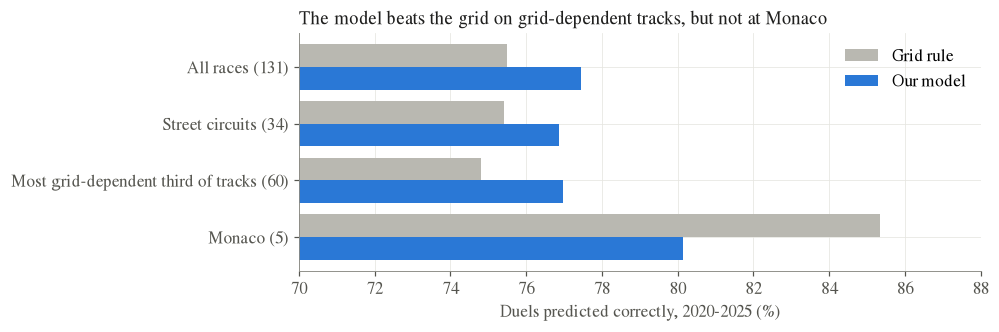

In [3]:
TR = S['tracks']
G = pd.DataFrame({k: v for k, v in TR.items() if isinstance(v, dict)}).T
G['gain_scorers'] = G.scorers_model - G.scorers_grid; G['gain_duels_pts'] = 100 * (G.duel_model - G.duel_grid)
display(G.round(3))
print('Most grid-dependent tracks (2014-2019):', ', '.join(TR['grid_dependent_tracks']))
print(f"Monaco 2014-2019: {TR['monaco_grid_dependence_2014_2019']:.0%} of top-10 finishers started top 10 (median track: {TR['grid_dependence_median_2014_2019']:.0%})")
fig, ax = plt.subplots(figsize=(8, 2.8)); y = np.arange(len(G))[::-1]
ax.barh(y + 0.2, G.duel_grid * 100, 0.4, color=GREY, label='Grid rule'); ax.barh(y - 0.2, G.duel_model * 100, 0.4, color=BLUE, label='Our model')
ax.set_yticks(y); ax.set_yticklabels([f"{n} ({int(r)})" for n, r in zip(G.index, G.races)]); ax.set_xlim(70, 88)
ax.set_xlabel('Duels predicted correctly, 2020-2025 (%)'); ax.legend(loc='upper right')
title(ax, 'The model beats the grid on grid-dependent tracks, but not at Monaco'); save(fig, '07_tracks'); plt.show()

**Reading.** At **Monaco the grid wins** (5 races): it names 9.2 of the 10 scorers against 8.0 for the model. Overtaking is almost impossible there, so any change the model makes to the grid order is a mistake. But Monaco is an exception, not a family: on the **third of tracks that depended most on the grid in 2014–2019** and on **street circuits**, the model still beats the grid. Monaco itself was *not* unusually grid-dependent in 2014–2019; it became so after 2021 (bigger cars), which is why a rule learnt from the past could not anticipate it.

### The answer to our question

In [4]:
a, b = S['2020-2025'], S['2026']
print(f"""Could we predict who finishes ahead, better than the grid?
  * Points (top 10):  YES on 2020-2025: {a['scorers_named']['Logistic regression']:.2f} vs {a['scorers_named']['Grid rule']:.2f} scorers per race (gain +{a['gain_vs_grid']['Logistic regression'][0]:.2f}, 95% CI {a['gain_vs_grid']['Logistic regression'][1]:+.2f} to {a['gain_vs_grid']['Logistic regression'][2]:+.2f}).
                      Not yet proven in 2026 ({b['scorers_named']['Logistic regression']:.2f} vs {b['scorers_named']['Grid rule']:.2f}, 17 races).
  * Duels (A vs B):   YES: {a['duel']['after']['accuracy']:.1%} vs {a['duel']['after']['grid_rule_accuracy']:.1%} (2020-2025) and {b['duel']['after']['accuracy']:.1%} vs {b['duel']['after']['grid_rule_accuracy']:.1%} (2026); both gains significant.
  * Winner:           the favourite is usually the pole sitter ({a['winner']['favourite_is_pole']:.0%} of races), so it wins as often ({a['winner']['favourite_won']:.0%}); the gain is in calibrated chances (log-loss {a['winner']['logloss']:.2f} vs {a['winner']['logloss_gridrate_baseline']:.2f}).
  * Before qualifying: worse than the grid. Saturday matters most.""")

Could we predict who finishes ahead, better than the grid?
  * Points (top 10):  YES on 2020-2025: 7.87 vs 7.71 scorers per race (gain +0.16, 95% CI +0.02 to +0.30).
                      Not yet proven in 2026 (7.59 vs 7.53, 17 races).
  * Duels (A vs B):   YES: 77.4% vs 75.5% (2020-2025) and 81.2% vs 78.9% (2026); both gains significant.
  * Winner:           the favourite is usually the pole sitter (86% of races), so it wins as often (55%); the gain is in calibrated chances (log-loss 1.37 vs 1.59).
  * Before qualifying: worse than the grid. Saturday matters most.


### Next: the live test
The real test is the races that have not happened yet: **United States (25 Oct), Mexico City (1 Nov), São Paulo (8 Nov), Las Vegas (22 Nov), Qatar (29 Nov), Abu Dhabi (6 Dec)**. Before each one, `python -m f1duel.forecast` publishes the predictions (committed to GitHub before the start, so the timestamp proves it), and the website shows *model vs reality* after each race.